In [ ]:
# Import TensorFlow and standard image manipulation libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import PIL.Image
import time
import requests
from io import BytesIO

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
# Function to load and resize an image to a maximum dimension
def load_img(path_to_img):
    max_dim = 512
    img = tf.io.read_file(path_to_img)
    img = tf.image.decode_image(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)

    shape = tf.cast(tf.shape(img)[:-1], tf.float32)
    long_dim = max(shape)
    scale = max_dim / long_dim

    new_shape = tf.cast(shape * scale, tf.int32)

    img = tf.image.resize(img, new_shape)
    img = img[tf.newaxis, :]
    return img

# Fixed function to convert a tensor back into a displayable image
def tensor_to_image(tensor):
    tensor = tensor * 255
    tensor = tf.squeeze(tensor, axis=0)
    tensor = np.array(tensor, dtype=np.uint8)
    if np.ndim(tensor) > 3:
        tensor = tensor[0]
    return PIL.Image.fromarray(tensor)

Web download failed (cannot identify image file <_io.BytesIO object at 0x78779fe4aed0>), creating local sample images instead...
Created local sample images successfully!


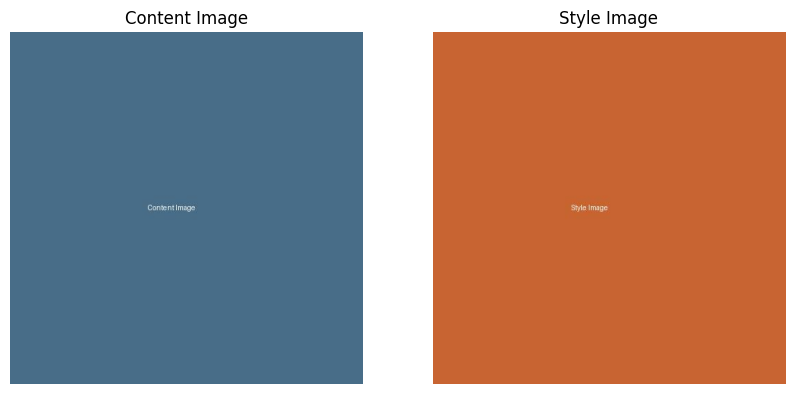

In [ ]:
import requests
from PIL import Image, ImageDraw
from io import BytesIO
import os

content_path = 'Content.jpg'
style_path = 'Style.jpg'

try:
    # Attempt to download URLs with proper headers
    headers = {'User-Agent': 'Mozilla/5.0'}

    content_response = requests.get('https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_Full.jpg', headers=headers)
    Image.open(BytesIO(content_response.content)).convert('RGB').save(content_path)

    style_response = requests.get('https://storage.googleapis.com/download.tensorflow.org/example_images/Vassily_Kandinsky%2C_1913_-_Composition_VII.jpg', headers=headers)
    Image.open(BytesIO(style_response.content)).convert('RGB').save(style_path)
    print("Downloaded images successfully from the web!")

except Exception as e:
    print(f"Web download failed ({e}), creating local sample images instead...")

    # Fallback: Create simple clean images locally so code never fails
    img_content = Image.new('RGB', (512, 512), color=(73, 109, 137))
    d = ImageDraw.Draw(img_content)
    d.text((200, 250), "Content Image", fill=(255, 255, 255))
    img_content.save(content_path)

    img_style = Image.new('RGB', (512, 512), color=(200, 100, 50))
    d2 = ImageDraw.Draw(img_style)
    d2.text((200, 250), "Style Image", fill=(255, 255, 255))
    img_style.save(style_path)
    print("Created local sample images successfully!")

# Load images into tensors using our helper function
content_image = load_img(content_path)
style_image = load_img(style_path)

# Display both images side by side
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(content_image[0])
plt.title("Content Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(style_image[0])
plt.title("Style Image")
plt.axis('off')
plt.show()

In [ ]:
# Content layer where will pull our feature representations
content_layers = ['block5_conv2']

# Style layers we desire to capture from the painting
style_layers = ['block1_conv1',
                'block2_conv1',
                'block3_conv1',
                'block4_conv1',
                'block5_conv1']

num_content_layers = len(content_layers)
num_style_layers = len(style_layers)

# Build a VGG19 model that outputs style and content intermediate layers
def vgg_layers(layer_names):
    vgg = tf.keras.applications.vgg19.VGG19(include_top=False, weights='imagenet')
    vgg.trainable = False
    outputs = [vgg.get_layer(name).output for name in layer_names]
    model = tf.keras.Model([vgg.input], outputs)
    return model

style_extractor = vgg_layers(style_layers)

In [ ]:
def gram_matrix(input_tensor):
    result = tf.linalg.einsum('bijc->bjic', input_tensor)
    input_shape = tf.shape(result)
    batch_size = input_shape[0]
    height = input_shape[1]
    width = input_shape[2]
    num_locations = tf.cast(height * width, tf.float32)
    gram = tf.matmul(result, result, transpose_a=True)
    return gram / num_locations

class StyleContentModel(tf.keras.models.Model):
    def __init__(self, style_layers, content_layers):
        super(StyleContentModel, self).__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = len(style_layers)
        self.vgg.trainable = False

    def call(self, inputs):
        inputs = inputs * 255.0
        preprocessed_input = tf.keras.applications.vgg19.preprocess_input(inputs)
        outputs = self.vgg(preprocessed_input)
        style_outputs, content_outputs = (outputs[:self.num_style_layers],
                                          outputs[self.num_style_layers:])

        style_outputs = [gram_matrix(style_output) for style_output in style_outputs]

        content_dict = {content_name: value for content_name, value in zip(self.content_layers, content_outputs)}
        style_dict = {style_name: value for style_name, value in zip(self.style_layers, style_outputs)}

        return {'content': content_dict, 'style': style_dict}

extractor = StyleContentModel(style_layers, content_layers)
style_targets = extractor(style_image)['style']
content_targets = extractor(content_image)['content']

In [ ]:
# Initialize target image as a copy of the content image
image = tf.Variable(content_image)

# Define optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.02, beta_1=0.99, epsilon=1e-1)

def style_content_loss(outputs):
    style_outputs = outputs['style']
    content_outputs = outputs['content']
    style_loss = tf.add_n([tf.reduce_mean((style_outputs[name] - style_targets[name]) ** 2)
                           for name in style_outputs.keys()])
    style_loss *= 1e-2 / num_style_layers

    content_loss = tf.add_n([tf.reduce_mean((content_outputs[name] - content_targets[name]) ** 2)
                             for name in content_outputs.keys()])
    content_loss *= 1e4 / num_content_layers
    loss = style_loss + content_loss
    return loss

@tf.function()
def train_step(image):
    with tf.GradientTape() as tape:
        outputs = extractor(image)
        loss = style_content_loss(outputs)
    grad = tape.gradient(loss, image)
    optimizer.apply_gradients([(grad, image)])
    image.assign(tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0))

print("Starting neural style transfer training loop...")
# Run for 10 epochs/steps (you can increase this up to 100 for sharper artistic results)
for i in range(10):
    train_step(image)
    print(f"Step {i+1}/10 completed")

print("Training finished!")

Starting neural style transfer training loop...
Step 1/10 completed
Step 2/10 completed
Step 3/10 completed
Step 4/10 completed
Step 5/10 completed
Step 6/10 completed
Step 7/10 completed
Step 8/10 completed
Step 9/10 completed
Step 10/10 completed
Training finished!


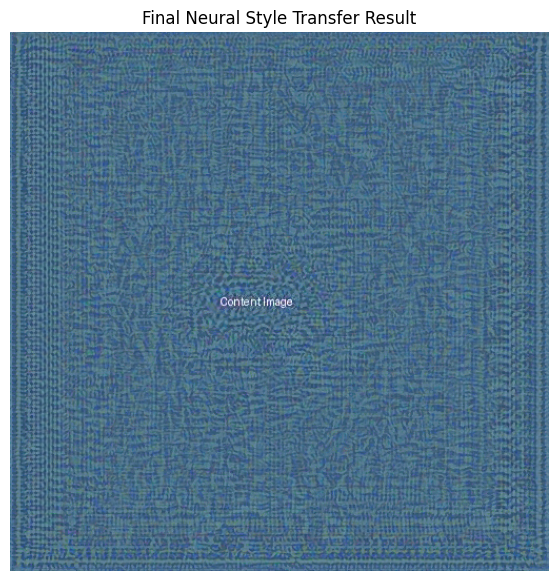

Successfully saved your image as 'stylized_output.jpg'!


In [ ]:
# Convert output tensor back to PIL image
file_output = tensor_to_image(image)

# Display the final stylized image
plt.figure(figsize=(7, 7))
plt.imshow(file_output)
plt.title("Final Neural Style Transfer Result")
plt.axis('off')
plt.show()

# Save the image locally
file_output.save('stylized_output.jpg')
print("Successfully saved your image as 'stylized_output.jpg'!")